# 30 — Similarity retrieval error analysis

Check whether the first CNN's physical mismatches recur across **all four variants, both directions and all three development holdout cases**. Read saved results from notebook 29; do not retrain, select a winner, or inspect final reserves.

The physical baseline favors these descriptors by construction. This analysis measures physical fidelity and disagreement, **not independent analog relevance**. The untrained encoder provides a second control. All results concern one seed and one EDA-exposed development split.

See [29: training experiment](29_similarity_cnn_experiment.ipynb) and [current decisions](../../../outline.md).

## Comparison rules

For every query, method and physical feature, calculate absolute candidate-minus-query differences. Report the top-ranked candidate and the mean difference across its five retrieved candidates separately. Never compare raw cosine scores with physical discrepancy scores.

Aggregate in two steps: median query error within each query region, then mean of those regional medians. Paired CNN-minus-control differences use the same query and candidate pool; positive values mean a larger physical mismatch. Fractions of worse/equal/better queries also receive equal region weight. These are descriptive summaries; neighboring queries and repeated comparisons are not independent statistical replicates.

Compare sampling modes on identical query IDs within each lunar view. Full-context and image-supported views can have different query locations and candidate availability, so differences between them combine support policy, selection and learned-model effects. Do not attribute them to architecture alone.

In [8]:
import json
import sys
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import rebase_links
from notebooks.shared.inspection import check_input, file_hash, verify_run

SOURCE = ROOT / "data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6"
DATASET = ROOT / "data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac"
NOTEBOOK = ROOT / "notebooks/modeling/terrain_similarity/30_similarity_error_analysis.ipynb"
OUT = ROOT / "data/processed/analysis" / ("similarity-errors-" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ"))
OUT.mkdir(parents=True, exist_ok=False)
expected = {**verify_run(SOURCE), **verify_run(DATASET)}
evidence = {str(p): file_hash(p) for p in [SOURCE / "provenance.json", DATASET / "provenance.json", NOTEBOOK, ROOT / "notebooks/shared/inspection.py"]}
FEATURE_UNITS = {"central_relief_m": "m", "slope_median_deg": "degrees", "slope_p90_deg": "degrees",
                 "local_sd_median_m": "m", "plane_residual_fraction": "fraction"}
GROUP = ["view", "sampling", "direction", "case"]
QUERY = GROUP + ["query_region", "query_id"]
METHODS = ["physical", "random_encoder", "cnn"]
provenance = {"status": "running", "source_run": str(SOURCE.relative_to(ROOT)),
              "dataset": str(DATASET.relative_to(ROOT)), "role": "development diagnostics only",
              "aggregation": "mean across query regions of within-region median absolute error",
              "gallery_selection": "both-heldout; worst and best paired top1 relief difference per direction and variant; ties by query ID",
              "python": sys.version, "pandas": pd.__version__, "numpy": np.__version__,
              "independent_relevance_validated": False, "reserves_opened": False}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")

673

## Validate saved results against patch measurements

Recompute physical differences from the patch manifest rather than trusting the ranking CSV's stored differences. Require all three methods to have the same query sets, five unique candidates per query, the expected body/fold direction and matching candidate-pool sizes. Verify hashes for every consumed artifact. Historical provenance retains the source paths used when its run was created.

In [9]:
patches = pd.read_csv(check_input(DATASET / "patches.csv", expected, evidence)).set_index("patch_id", verify_integrity=True)
frames = []
for view in ["full_context", "image_supported"]:
    for sampling in ["region_balanced", "count_weighted"]:
        folder = SOURCE / view / sampling
        frame = pd.read_csv(check_input(folder / "retrieval.csv", expected, evidence))
        query_info = pd.read_csv(check_input(folder / "query_comparison.csv", expected, evidence))
        assert set(frame["method"]) == set(METHODS)
        assert set(frame["direction"]) == {"earth_to_moon", "moon_to_earth"}
        assert set(frame["case"]) == {"heldout_queries", "heldout_candidates", "both_heldout"}
        keys = ["direction", "case", "query_id", "method"]
        assert not frame.duplicated(keys + ["rank"]).any()
        assert not frame.duplicated(keys + ["candidate_id"]).any()
        assert frame.groupby(keys)["rank"].apply(lambda s: sorted(s) == [1, 2, 3, 4, 5]).all()
        assert (frame.groupby(["direction", "case", "query_id"])["method"].nunique() == 3).all()
        assert not query_info.duplicated(keys).any()
        assert set(map(tuple, frame[keys].drop_duplicates().to_numpy())) == set(map(tuple, query_info[keys].to_numpy()))
        assert (query_info.groupby(["direction", "case", "query_id"])["candidate_count"].nunique() == 1).all()
        query_patch = patches.loc[frame["query_id"]].reset_index(drop=True)
        candidate_patch = patches.loc[frame["candidate_id"]].reset_index(drop=True)
        assert (query_patch["body"].to_numpy() != candidate_patch["body"].to_numpy()).all()
        np.testing.assert_array_equal(frame["direction"], query_patch["body"] + "_to_" + candidate_patch["body"])
        np.testing.assert_array_equal(frame["query_region"], query_patch["region"])
        np.testing.assert_array_equal(query_patch["fold"], np.where(frame["case"] == "heldout_candidates", "train", "holdout"))
        np.testing.assert_array_equal(candidate_patch["fold"], np.where(frame["case"] == "heldout_queries", "train", "holdout"))
        for feature in FEATURE_UNITS:
            delta = candidate_patch[feature].to_numpy() - query_patch[feature].to_numpy()
            np.testing.assert_allclose(frame[f"delta_{feature}"], delta, rtol=1e-7, atol=1e-7)
            frame[f"error_{feature}"] = np.abs(delta)
        frame["view"], frame["sampling"] = view, sampling
        frames.append(frame)
rankings = pd.concat(frames, ignore_index=True)
for view, group in rankings.groupby("view"):
    balanced = group.loc[group["sampling"] == "region_balanced", ["direction", "case", "query_id"]].drop_duplicates()
    counted = group.loc[group["sampling"] == "count_weighted", ["direction", "case", "query_id"]].drop_duplicates()
    assert set(map(tuple, balanced.to_numpy())) == set(map(tuple, counted.to_numpy()))
print(len(rankings), "ranking rows verified")

26880 ranking rows verified


## Physical mismatch summaries

Central relief is P95 minus P05 elevation. Local elevation SD is not a direct measure of rocks or boulders. Plane residual fraction describes departure from a fitted plane; it is only a coarse spatial-form descriptor, not a complete morphology judgment.

The top-five mean describes the whole shortlist; it is not an oracle choosing whichever candidate happens to minimize one feature. Keep each physical dimension separate instead of inventing a universal suitability score.

In [10]:
errors = rankings.melt(id_vars=QUERY + ["method", "rank"], value_vars=[f"error_{f}" for f in FEATURE_UNITS],
                        var_name="feature", value_name="absolute_error")
errors["feature"] = errors["feature"].str.removeprefix("error_")
top1 = errors.loc[errors["rank"] == 1].drop(columns="rank").assign(scope="top1")
top5 = errors.groupby(QUERY + ["method", "feature"], as_index=False)["absolute_error"].mean().assign(scope="top5_mean")
query_errors = pd.concat([top1, top5], ignore_index=True)
region_keys = GROUP + ["query_region", "scope", "method", "feature"]
regional = query_errors.groupby(region_keys, as_index=False).agg(
    median_absolute_error=("absolute_error", "median"), queries=("query_id", "nunique"))
macro = regional.groupby(GROUP + ["scope", "method", "feature"], as_index=False).agg(
    mean_region_median=("median_absolute_error", "mean"), query_regions=("query_region", "nunique"), queries=("queries", "sum"))
query_errors.to_csv(OUT / "query_physical_errors.csv", index=False)
regional.to_csv(OUT / "errors_by_region.csv", index=False)
macro.to_csv(OUT / "errors_region_macro.csv", index=False)
relief = macro.loc[(macro["scope"] == "top1") & (macro["feature"] == "central_relief_m")].pivot(
    index=GROUP, columns="method", values="mean_region_median").reset_index()
display(relief.round(2))

method,view,sampling,direction,case,cnn,physical,random_encoder
0,full_context,count_weighted,earth_to_moon,both_heldout,39.38,11.11,8.93
1,full_context,count_weighted,earth_to_moon,heldout_candidates,42.15,16.20,24.70
2,full_context,count_weighted,earth_to_moon,heldout_queries,33.17,4.87,9.37
3,full_context,count_weighted,moon_to_earth,both_heldout,46.56,5.22,16.92
4,full_context,count_weighted,moon_to_earth,heldout_candidates,38.22,6.85,12.07
5,full_context,count_weighted,moon_to_earth,heldout_queries,98.79,28.93,49.99
6,full_context,region_balanced,earth_to_moon,both_heldout,64.09,11.11,8.93
7,full_context,region_balanced,earth_to_moon,heldout_candidates,79.12,16.20,24.70
8,full_context,region_balanced,earth_to_moon,heldout_queries,5.61,4.87,9.37
9,full_context,region_balanced,moon_to_earth,both_heldout,35.31,5.22,16.92


In [11]:
paired = query_errors.pivot(index=QUERY + ["scope", "feature"], columns="method", values="absolute_error").reset_index()
assert paired[METHODS].notna().all().all()
comparisons = []
for control in ["physical", "random_encoder"]:
    part = paired[QUERY + ["scope", "feature"]].copy()
    part["control"] = control
    part["cnn_minus_control"] = paired["cnn"] - paired[control]
    part["worse"] = part["cnn_minus_control"] > 1e-7
    part["better"] = part["cnn_minus_control"] < -1e-7
    part["equal"] = ~(part["worse"] | part["better"])
    comparisons.append(part)
paired_differences = pd.concat(comparisons, ignore_index=True)
paired_regions = paired_differences.groupby(GROUP + ["query_region", "scope", "feature", "control"], as_index=False).agg(
    median_paired_difference=("cnn_minus_control", "median"), worse_fraction=("worse", "mean"),
    better_fraction=("better", "mean"), equal_fraction=("equal", "mean"), queries=("query_id", "nunique"))
paired_macro = paired_regions.groupby(GROUP + ["scope", "feature", "control"], as_index=False).agg(
    mean_region_median_paired_difference=("median_paired_difference", "mean"),
    mean_region_worse_fraction=("worse_fraction", "mean"), mean_region_better_fraction=("better_fraction", "mean"),
    mean_region_equal_fraction=("equal_fraction", "mean"), query_regions=("query_region", "nunique"))
paired_differences.to_csv(OUT / "paired_query_differences.csv", index=False)
paired_regions.to_csv(OUT / "paired_by_region.csv", index=False)
paired_macro.to_csv(OUT / "paired_region_macro.csv", index=False)
summary_rows = []
for (scope, feature), group in macro.groupby(["scope", "feature"]):
    table = group.pivot(index=GROUP, columns="method", values="mean_region_median")
    for control in ["physical", "random_encoder"]:
        summary_rows.append({"scope": scope, "feature": feature, "control": control,
                             "comparison_cells": len(table), "cnn_larger_error_cells": int((table["cnn"] > table[control] + 1e-7).sum())})
summary = pd.DataFrame(summary_rows)
summary.to_csv(OUT / "comparison_cell_counts.csv", index=False)
display(summary.loc[summary["scope"] == "top1"])
# Independently check one summary using the original ranking rows.
check = rankings.loc[(rankings["view"] == "full_context") & (rankings["sampling"] == "region_balanced")
                     & (rankings["direction"] == "earth_to_moon") & (rankings["case"] == "both_heldout")
                     & (rankings["method"] == "cnn") & (rankings["rank"] == 1)]
assert len(check) == 32 and check["query_region"].nunique() == 1
np.testing.assert_allclose(np.median(np.abs(check["delta_central_relief_m"])), 64.08790283203144, atol=1e-6)


,scope,feature,control,comparison_cells,cnn_larger_error_cells
0,top1,central_relief_m,physical,24,24
1,top1,central_relief_m,random_encoder,24,23
2,top1,local_sd_median_m,physical,24,23
3,top1,local_sd_median_m,random_encoder,24,24
4,top1,plane_residual_fraction,physical,24,22
5,top1,plane_residual_fraction,random_encoder,24,15
6,top1,slope_median_deg,physical,24,22
7,top1,slope_median_deg,random_encoder,24,24
8,top1,slope_p90_deg,physical,24,21
9,top1,slope_p90_deg,random_encoder,24,18


## Inspect disagreement in both directions

For each variant and direction, select the queries with the **largest and smallest paired top-ranked relief-error difference** between CNN and physical baseline. These are deliberately targeted diagnostic examples, not a representative gallery or independent labels. A smallest difference may still be a CNN failure; inspect its sign.

Each row shows query, physical-baseline candidate and CNN candidate. All panels in a row share one physical elevation color scale. Titles report relief and P90 slope so a similar color pattern cannot conceal a different amplitude. Rotation-invariant retrieval can legitimately return a differently oriented patch for this morphology-only task.

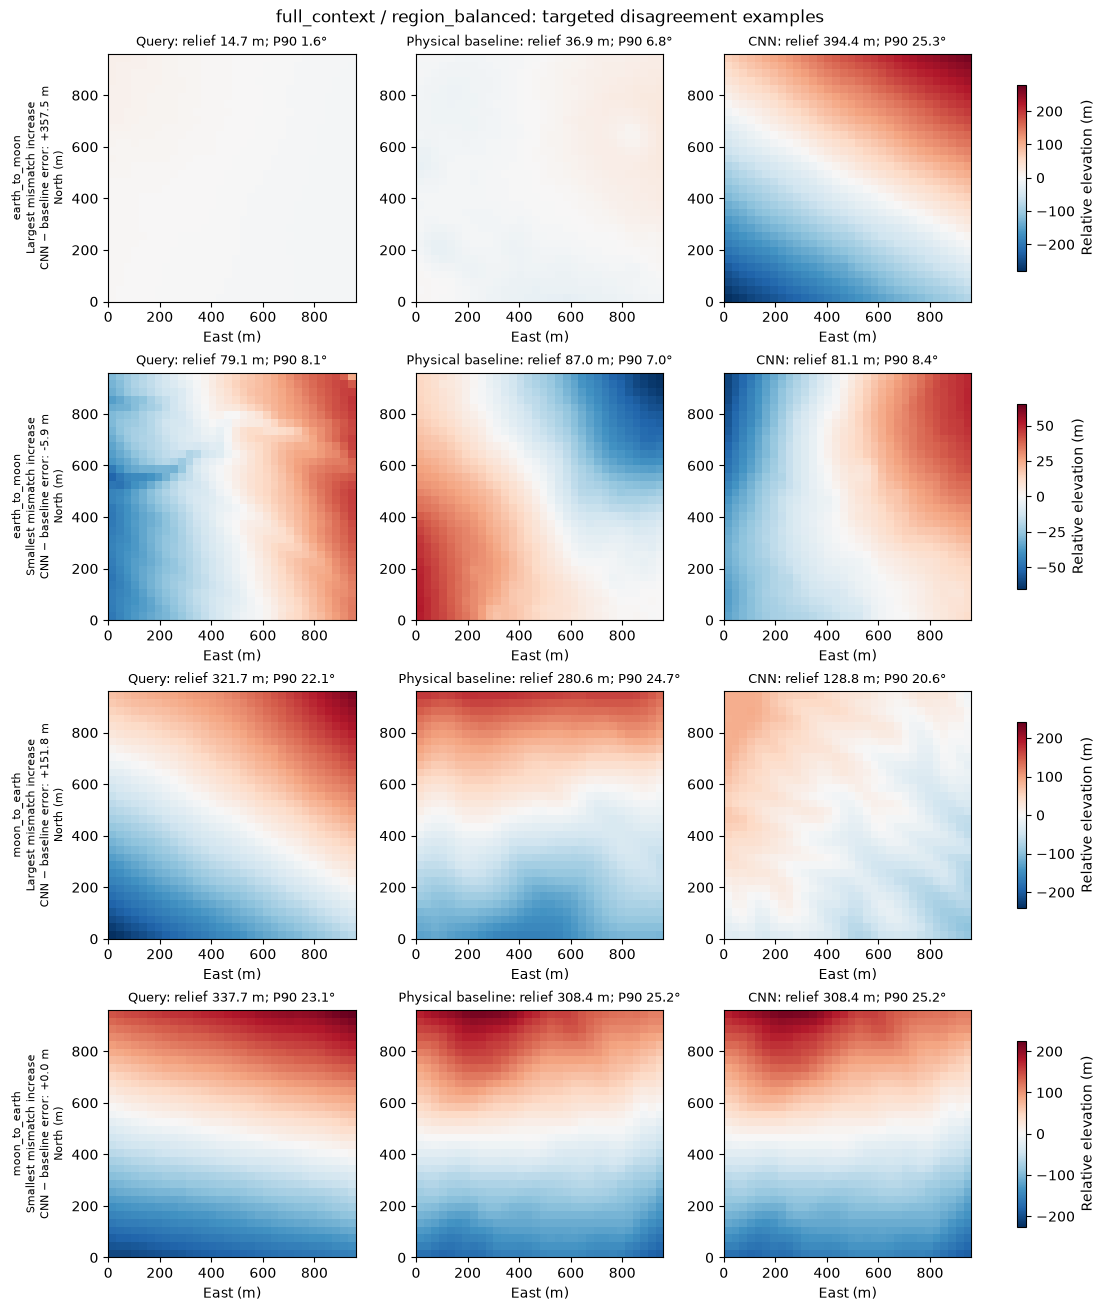

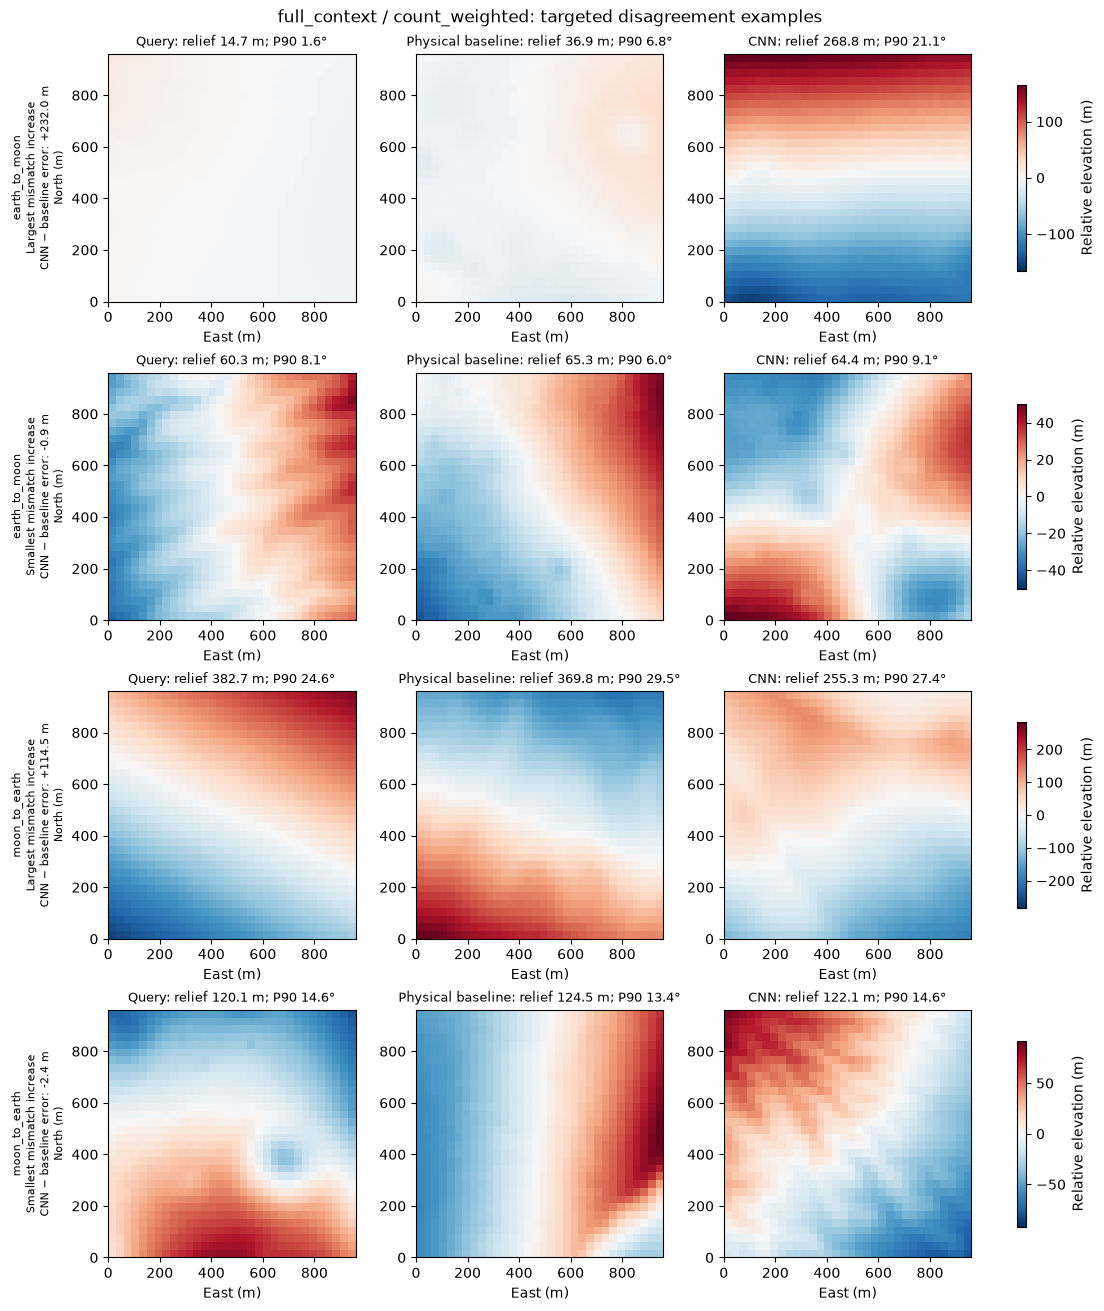

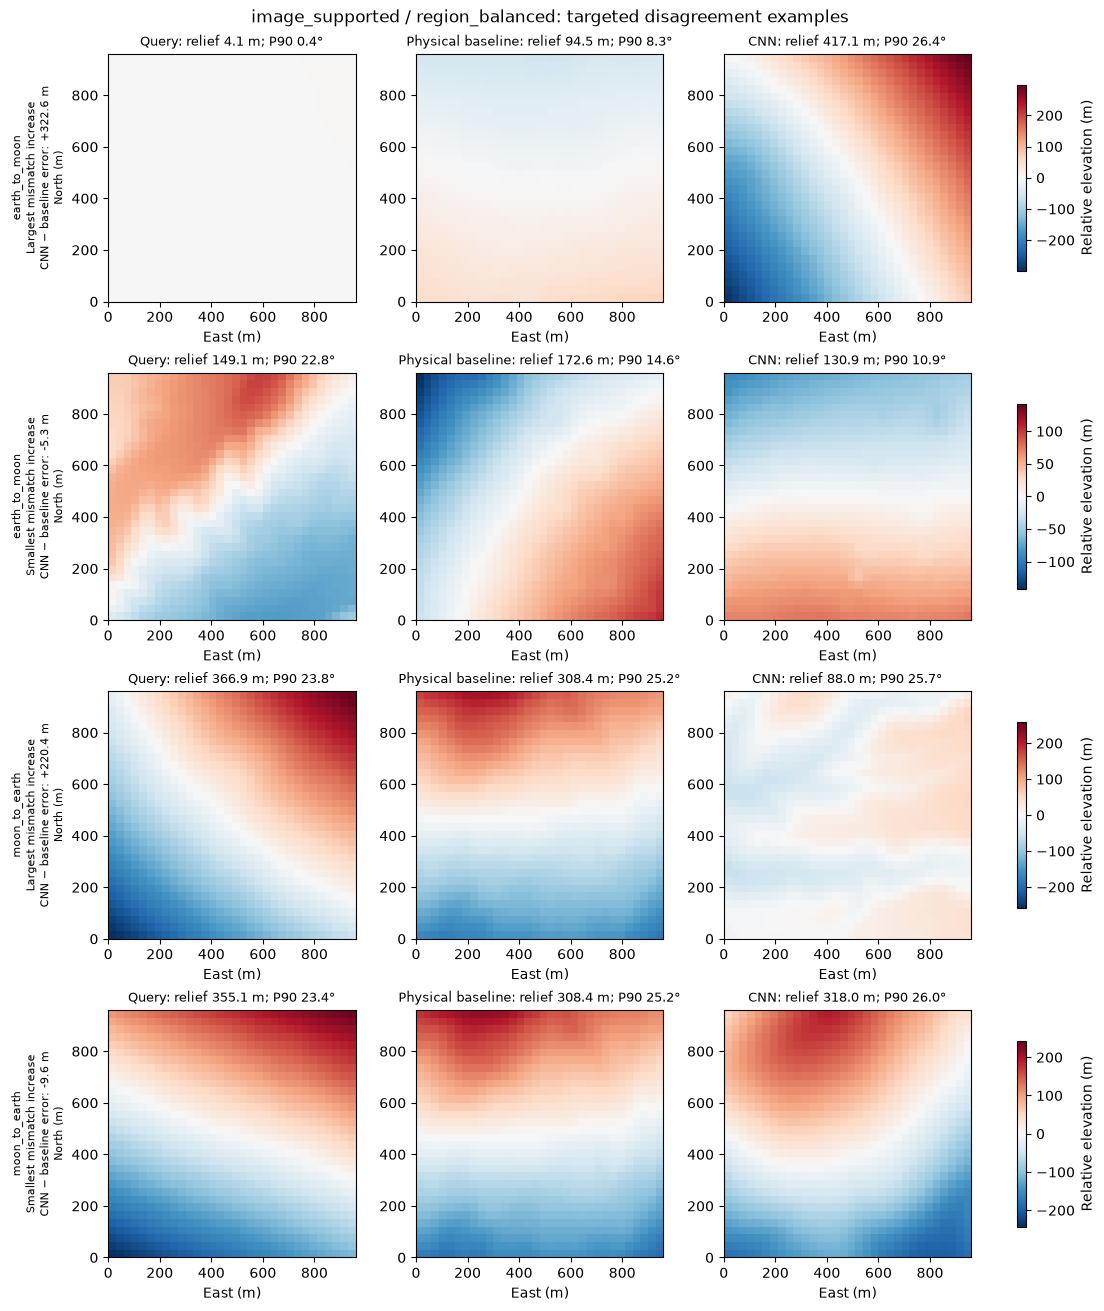

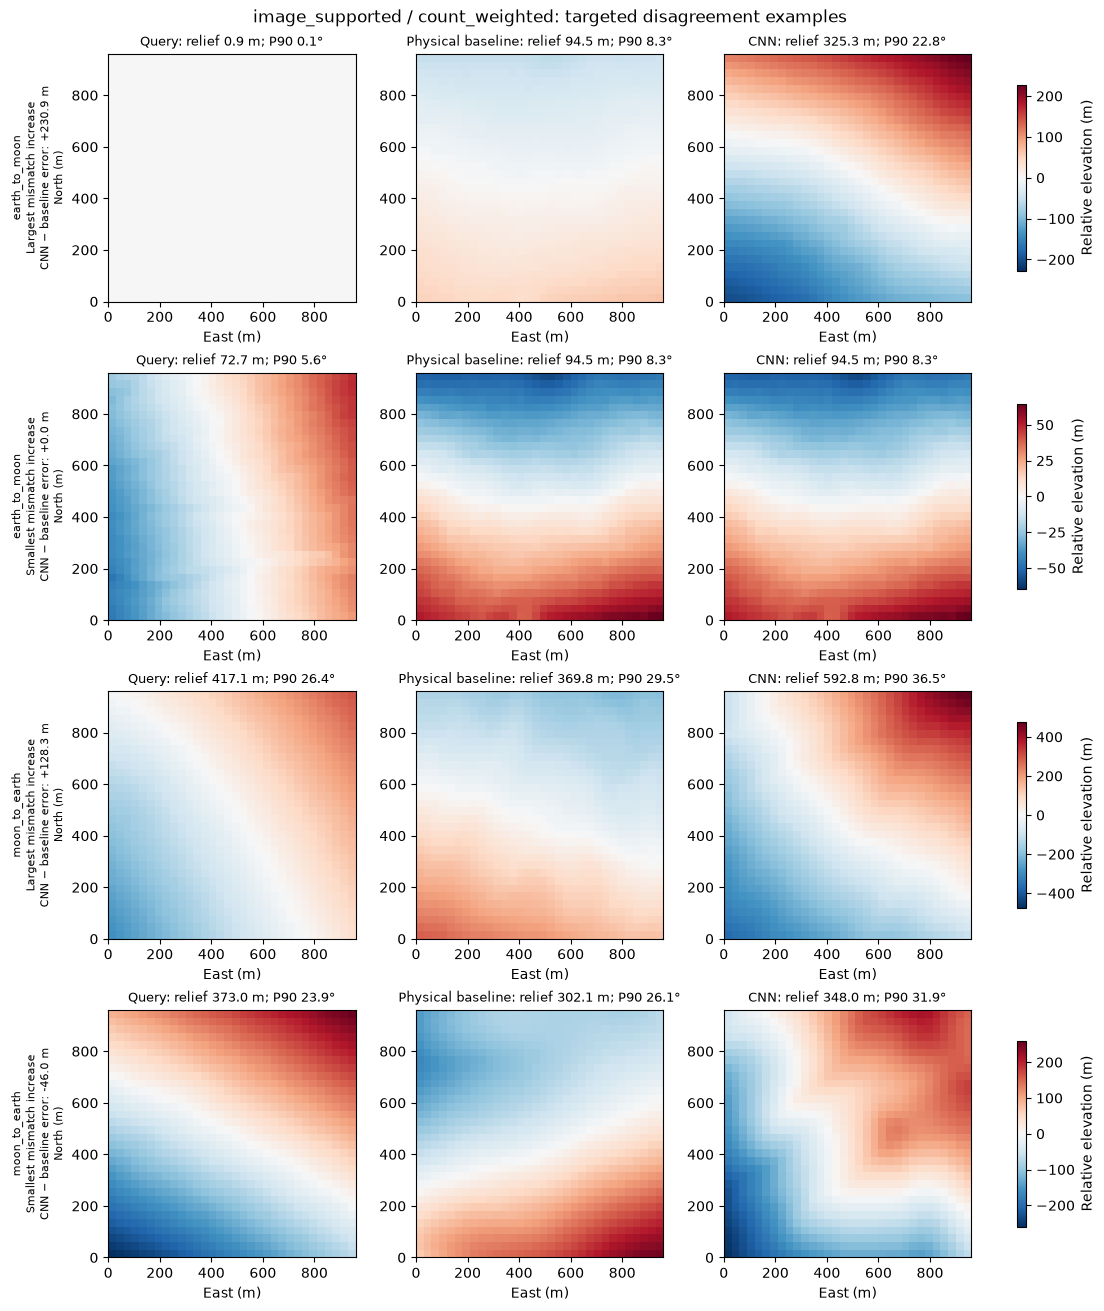

,view,sampling,direction,selection,paired_relief_error_difference_m
0,full_context,region_balanced,earth_to_moon,Largest mismatch increase,357.484985
1,full_context,region_balanced,earth_to_moon,Smallest mismatch increase,-5.899414
2,full_context,region_balanced,moon_to_earth,Largest mismatch increase,151.803772
3,full_context,region_balanced,moon_to_earth,Smallest mismatch increase,0.000000
4,full_context,count_weighted,earth_to_moon,Largest mismatch increase,231.960034
5,full_context,count_weighted,earth_to_moon,Smallest mismatch increase,-0.902686
6,full_context,count_weighted,moon_to_earth,Largest mismatch increase,114.507715
7,full_context,count_weighted,moon_to_earth,Smallest mismatch increase,-2.420679
8,image_supported,region_balanced,earth_to_moon,Largest mismatch increase,322.622949
9,image_supported,region_balanced,earth_to_moon,Smallest mismatch increase,-5.315967


In [12]:
gallery_rows = []
cache = {}
for view in ["full_context", "image_supported"]:
    for sampling in ["region_balanced", "count_weighted"]:
        part = paired_differences.loc[(paired_differences["view"] == view) & (paired_differences["sampling"] == sampling)
                                      & (paired_differences["case"] == "both_heldout") & (paired_differences["scope"] == "top1")
                                      & (paired_differences["feature"] == "central_relief_m") & (paired_differences["control"] == "physical")]
        fig, axes = plt.subplots(4, 3, figsize=(11, 13), constrained_layout=True)
        row_number = 0
        for direction in ["earth_to_moon", "moon_to_earth"]:
            ordered = part.loc[part["direction"] == direction].sort_values(["cnn_minus_control", "query_id"])
            for label, chosen in [("Largest mismatch increase", ordered.iloc[-1]), ("Smallest mismatch increase", ordered.iloc[0])]:
                query_id = chosen["query_id"]
                matches = rankings.loc[(rankings["view"] == view) & (rankings["sampling"] == sampling)
                                       & (rankings["case"] == "both_heldout") & (rankings["query_id"] == query_id)
                                       & (rankings["rank"] == 1)].set_index("method")
                ids = [query_id, matches.loc["physical", "candidate_id"], matches.loc["cnn", "candidate_id"]]
                images = []
                for patch_id in ids:
                    record = patches.loc[patch_id]
                    shard = record["shard"]
                    if shard not in cache:
                        with np.load(check_input(DATASET / shard, expected, evidence), allow_pickle=False) as stored:
                            cache[shard] = stored["physical"][:, 0].copy()
                    images.append(cache[shard][int(record["tensor_index"])])
                limit = max(float(np.max(np.abs(values))) for values in images) or 1.
                for column, (patch_id, title, values) in enumerate(zip(ids, ["Query", "Physical baseline", "CNN"], images, strict=True)):
                    record = patches.loc[patch_id]
                    im = axes[row_number, column].imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, extent=(0, 960, 0, 960))
                    axes[row_number, column].set_title(f"{title}: relief {record['central_relief_m']:.1f} m; P90 {record['slope_p90_deg']:.1f}°", fontsize=9)
                    axes[row_number, column].set_xlabel("East (m)")
                axes[row_number, 0].set_ylabel(f"{direction}\n{label}\nCNN − baseline error: {chosen['cnn_minus_control']:+.1f} m\nNorth (m)", fontsize=8)
                fig.colorbar(im, ax=list(axes[row_number]), label="Relative elevation (m)", shrink=.75)
                gallery_rows.append({"view": view, "sampling": sampling, "direction": direction, "selection": label,
                                     "query_id": query_id, "physical_id": ids[1], "cnn_id": ids[2],
                                     "paired_relief_error_difference_m": chosen["cnn_minus_control"]})
                row_number += 1
        fig.suptitle(f"{view} / {sampling}: targeted disagreement examples", fontsize=12)
        fig.savefig(OUT / f"gallery_{view}_{sampling}.png", dpi=120)
        plt.show()
        plt.close(fig)
pd.DataFrame(gallery_rows).to_csv(OUT / "gallery_selections.csv", index=False)
display(pd.DataFrame(gallery_rows)[["view", "sampling", "direction", "selection", "paired_relief_error_difference_m"]])

## Findings and next decision

For the pinned first run, top-ranked relief mismatch is larger for the trained CNN than the physical baseline in **24 of 24 comparison cells**, and larger than the untrained encoder in **23 of 24**. These cells reuse queries and candidate regions; they are not independent experiments or a statistical significance claim. The physical baseline directly optimizes related descriptors, and the comparison does not establish which method best captures mission-relevant morphology.

The evidence supports investigating physical fidelity before extending training. The current objective rewards recognition of rotated copies and treats many distinct patches as negatives; it does not explicitly teach Earth–Moon relevance. The cause of the observed mismatch is still unresolved. Do not infer that output normalization, rotations or insufficient epochs are individually responsible without a controlled comparison.

Keep physical descriptors alongside embeddings. Next, audit sensitivity to controlled changes in physical amplitude and inspect morphology with an agreed independent rubric. If physical fidelity is required by that rubric, compare physical filtering/reranking or physically informed training as explicit experiments. Do not create arbitrary equipment thresholds, label pairs from the same baseline being evaluated, promote a model from these summaries, or open final reserves.

No models are retrained or selected here. The pooled relevance worksheet from notebook 29 remains unlabeled.

In [13]:
# Save the notebook's Markdown as the report; explanatory notes stay in Markdown cells.
notebook = nbformat.read(NOTEBOOK, as_version=4)
report = "\n\n".join(cell.source for cell in notebook.cells if cell.cell_type == "markdown")
report = rebase_links(report, NOTEBOOK, OUT / "REPORT.md", {})
# Notebook-relative links would be misleading from the output folder.
(OUT / "REPORT.md").write_text(report + "\n", encoding="utf-8")
provenance["inputs"] = evidence
provenance["outputs"] = {str(p.relative_to(OUT)): file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != "provenance.json"}
provenance["status"] = "publishing"
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print("Completed:", OUT)
print("24 comparison cells per feature/scope; shared queries mean these are not independent tests.")


Completed: .\data\processed\analysis\similarity-errors-20261102T143639914729Z
24 comparison cells per feature/scope; shared queries mean these are not independent tests.


## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [14]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\similarity-errors-20261102T143639914729Z
Disposable reports: .\reports\analysis\similarity-errors-20261102T143639914729Z
